In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [62]:
data_triage = pd.read_csv("Clasificación_en_Triage_Urgencias_20261003.csv")

print("Dimensiones:", data_triage.shape)
print("\nColumnas:", data_triage.columns.tolist())

Dimensiones: (89453, 9)

Columnas: ['CodAdminis', 'Nom_Admini', 'Fecha_Ing', 'Hora_Ingre', 'Fecha_Atencion', 'Hora_Atencion', 'Triage', 'Ips', 'Red']


In [63]:
data_triage.head()

,CodAdminis,Nom_Admini,Fecha_Ing,Hora_Ingre,Fecha_Atencion,Hora_Atencion,Triage,Ips,Red
0,ESS118,EMSSANAR S.A.S,2020 Jan 23 08:29:02 AM,1900 Jan 01 08:29:00 AM,2020 Jan 23 08:36:00 AM,1900 Jan 01 08:36:00 AM,III,HOSPITAL LOCAL CIVIL,RED NORTE
1,ESS118,EMSSANAR S.A.S,2020 Jan 23 08:29:02 AM,1900 Jan 01 08:29:00 AM,2020 Jan 23 08:36:00 AM,1900 Jan 01 08:36:00 AM,III,HOSPITAL LOCAL CIVIL,RED NORTE
2,ESS118,EMSSANAR S.A.S,2020 Jan 14 09:27:46 AM,1900 Jan 01 09:27:00 AM,2020 Jan 14 10:18:00 AM,1900 Jan 01 10:18:00 AM,III,HOSPITAL LOCAL CIVIL,RED NORTE
3,ESS118,EMSSANAR S.A.S,2020 Feb 29 09:01:31 AM,1900 Jan 01 09:01:00 AM,2020 Feb 29 09:11:00 AM,1900 Jan 01 09:11:00 AM,III,CENTRO HOSPITAL LA ROSA,RED SUR
4,ESS118,EMSSANAR S.A.S,2020 Feb 09 05:26:00 PM,1900 Jan 01 05:26:00 PM,2020 Feb 09 05:50:00 PM,1900 Jan 01 05:50:00 PM,III,HOSPITAL LOCAL CIVIL,RED NORTE


In [64]:
data_triage.info()

<class 'pandas.DataFrame'>
RangeIndex: 89453 entries, 0 to 89452
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   CodAdminis      89452 non-null  str  
 1   Nom_Admini      89452 non-null  str  
 2   Fecha_Ing       89453 non-null  str  
 3   Hora_Ingre      89453 non-null  str  
 4   Fecha_Atencion  89453 non-null  str  
 5   Hora_Atencion   89453 non-null  str  
 6   Triage          89453 non-null  str  
 7   Ips             89453 non-null  str  
 8   Red             89453 non-null  str  
dtypes: str(9)
memory usage: 6.1 MB


In [65]:
datos = data_triage.copy()
datos.columns = datos.columns.str.strip().str.lower()

columnas = [
    "fecha_ing", "hora_ingre",
    "fecha_atencion", "hora_atencion",
    "triage", "ips"
]

faltantes = set(columnas) - set(datos.columns)
print("Columnas faltantes:", faltantes)

if faltantes:
    raise ValueError("Revisa los nombres de columnas antes de continuar.")

Columnas faltantes: set()


In [66]:
datos["fecha_ing_parseada"] = pd.to_datetime(
    datos["fecha_ing"], errors="coerce"
)

conteo_anual = (
    datos.groupby(datos["fecha_ing_parseada"].dt.year, dropna=False)
         .size()
         .rename("registros")
         .reset_index()
)

display(conteo_anual)
print("Fechas no interpretadas:", datos["fecha_ing_parseada"].isna().sum())

,fecha_ing_parseada,registros
0,2020,19862
1,2021,27429
2,2022,42162


Fechas no interpretadas: 0


In [67]:
inicio = pd.Timestamp("2022-01-01")  # Cambiar según el conteo
fin_exclusivo = pd.Timestamp("2023-01-01")

periodo = datos.loc[
    datos["fecha_ing_parseada"].ge(inicio)
    & datos["fecha_ing_parseada"].lt(fin_exclusivo)
].copy()

print("Registros en el período:", len(periodo))
print("Primera fecha:", periodo["fecha_ing_parseada"].min())
print("Última fecha:", periodo["fecha_ing_parseada"].max())
display(periodo["triage"].value_counts(dropna=False))

Registros en el período: 42162
Primera fecha: 2022-01-01 00:29:01
Última fecha: 2022-09-29 23:45:00


triage
III    36288
IV      4280
II      1254
V        268
I         72
Name: count, dtype: int64

In [68]:
def combinar_fecha_hora(tabla, columna_fecha, columna_hora):
    fecha = pd.to_datetime(tabla[columna_fecha], errors="coerce")

    texto_hora = tabla[columna_hora].astype("string").str.strip()
    hora_extraida = texto_hora.str.extract(
        r"(\d{1,2}:\d{2}(?::\d{2})?\s*(?:AM|PM)?)\s*$",
        flags=2
    )[0]

    hora = pd.to_datetime(
        hora_extraida, errors="coerce", format="mixed"
    )

    segundos = (
        hora.dt.hour * 3600
        + hora.dt.minute * 60
        + hora.dt.second
    )

    return fecha.dt.normalize() + pd.to_timedelta(segundos, unit="s")


periodo["ingreso_dt"] = combinar_fecha_hora(
    periodo, "fecha_ing", "hora_ingre"
)
periodo["atencion_dt"] = combinar_fecha_hora(
    periodo, "fecha_atencion", "hora_atencion"
)

periodo["minutos"] = (
    periodo["atencion_dt"] - periodo["ingreso_dt"]
).dt.total_seconds() / 60

print("Sin tiempo calculable:", periodo["minutos"].isna().sum())
print("Tiempos negativos:", (periodo["minutos"] < 0).sum())
display(periodo[["ingreso_dt", "atencion_dt", "minutos", "triage"]].head(10))

Sin tiempo calculable: 0
Tiempos negativos: 6


,ingreso_dt,atencion_dt,minutos,triage
47291,2022-01-01 01:38:00,2022-01-01 01:49:00,11.0,II
47292,2022-01-25 13:16:00,2022-01-25 14:06:00,50.0,III
47293,2022-03-17 09:23:00,2022-03-17 10:02:00,39.0,III
47294,2022-03-02 19:36:00,2022-03-02 20:43:00,67.0,III
47295,2022-01-29 14:35:00,2022-01-29 15:05:00,30.0,III
47296,2022-01-07 06:47:00,2022-01-07 06:50:00,3.0,III
47297,2022-01-21 07:56:00,2022-01-21 08:38:00,42.0,III
47298,2022-02-26 12:43:00,2022-02-26 14:32:00,109.0,III
47299,2022-03-25 21:00:00,2022-03-25 21:47:00,47.0,III
47300,2022-01-02 08:32:00,2022-01-02 08:35:00,3.0,III


In [69]:
columnas_revision = [
    "fecha_ing", "hora_ingre",
    "fecha_atencion", "hora_atencion",
    "ingreso_dt", "atencion_dt", "minutos", "triage", "ips"
]

display(
    periodo.loc[periodo["minutos"] < 0, columnas_revision]
           .sort_values("minutos")
)

,fecha_ing,hora_ingre,fecha_atencion,hora_atencion,ingreso_dt,atencion_dt,minutos,triage,ips
74128,2022 Jul 16 12:00:00 AM,1900 Jan 01 11:59:00 PM,2022 Jul 16 12:06:00 AM,1900 Jan 01 12:06:00 AM,2022-07-16 23:59:00,2022-07-16 00:06:00,-1433.0,III,CS SAN VICENTE
87275,2022 Sep 06 12:00:00 AM,1900 Jan 01 11:59:00 PM,2022 Sep 06 12:21:00 AM,1900 Jan 01 12:21:00 AM,2022-09-06 23:59:00,2022-09-06 00:21:00,-1418.0,III,CS SAN VICENTE
65741,2022 Jun 28 12:00:00 AM,1900 Jan 01 11:59:00 PM,2022 Jun 28 12:26:00 AM,1900 Jan 01 12:26:00 AM,2022-06-28 23:59:00,2022-06-28 00:26:00,-1413.0,III,CENTRO HOSPITAL LA ROSA
66587,2022 Jun 27 12:00:00 AM,1900 Jan 01 11:59:00 PM,2022 Jun 27 12:32:00 AM,1900 Jan 01 12:32:00 AM,2022-06-27 23:59:00,2022-06-27 00:32:00,-1407.0,III,CS SAN VICENTE
76271,2022 Jul 17 12:00:00 AM,1900 Jan 01 11:59:00 PM,2022 Jul 17 01:05:00 AM,1900 Jan 01 01:05:00 AM,2022-07-17 23:59:00,2022-07-17 01:05:00,-1374.0,III,CENTRO HOSPITAL LA ROSA
69414,2022 Jun 24 12:00:00 AM,1900 Jan 01 11:59:00 PM,2022 Jun 24 01:10:00 AM,1900 Jan 01 01:10:00 AM,2022-06-24 23:59:00,2022-06-24 01:10:00,-1369.0,III,HOSPITAL LOCAL CIVIL


In [70]:
# Versión principal: excluir intervalos negativos
analisis = periodo.loc[periodo["minutos"] >= 0].copy()

# Versión de sensibilidad: corregir únicamente el patrón observado
sensibilidad = periodo.copy()

patron_medianoche = (
    sensibilidad["minutos"].lt(0)
    & sensibilidad["ingreso_dt"].dt.strftime("%H:%M").eq("23:59")
    & sensibilidad["atencion_dt"].dt.hour.isin([0, 1])
    & sensibilidad["ingreso_dt"].dt.date.eq(
        sensibilidad["atencion_dt"].dt.date
    )
)

print("Registros que cumplen el patrón:", patron_medianoche.sum())

sensibilidad.loc[patron_medianoche, "atencion_dt"] += pd.Timedelta(days=1)
sensibilidad["minutos"] = (
    sensibilidad["atencion_dt"] - sensibilidad["ingreso_dt"]
).dt.total_seconds() / 60

display(sensibilidad.loc[patron_medianoche, ["ingreso_dt", "atencion_dt", "minutos"]])
print("Negativos restantes:", (sensibilidad["minutos"] < 0).sum())

Registros que cumplen el patrón: 6


,ingreso_dt,atencion_dt,minutos
65741,2022-06-28 23:59:00,2022-06-29 00:26:00,27.0
66587,2022-06-27 23:59:00,2022-06-28 00:32:00,33.0
69414,2022-06-24 23:59:00,2022-06-25 01:10:00,71.0
74128,2022-07-16 23:59:00,2022-07-17 00:06:00,7.0
76271,2022-07-17 23:59:00,2022-07-18 01:05:00,66.0
87275,2022-09-06 23:59:00,2022-09-07 00:21:00,22.0


Negativos restantes: 0


In [71]:
# Comprobar que ambas versiones están listas
print("Principal:", len(analisis))
print("Sensibilidad:", len(sensibilidad))
print("Negativos en sensibilidad:", (sensibilidad["minutos"] < 0).sum())

# Descriptivos de la variable principal
resumen = analisis["minutos"].agg(
    ["count", "mean", "median", "std", "min", "max", "skew"]
)
display(resumen.to_frame(name="tiempo_minutos"))

display(
    analisis["minutos"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

# Tamaño de cada grupo de triage
display(analisis["triage"].value_counts(dropna=False))

Principal: 42156
Sensibilidad: 42162
Negativos en sensibilidad: 0


,tiempo_minutos
count,42156.000000
mean,63.506262
median,47.000000
std,53.934997
min,0.000000
max,360.000000
skew,1.245361


count    42156.000000
mean        63.506262
std         53.934997
min          0.000000
25%         21.000000
50%         47.000000
75%         94.000000
90%        145.000000
95%        172.000000
99%        211.000000
max        360.000000
Name: minutos, dtype: float64

triage
III    36282
IV      4280
II      1254
V        268
I         72
Name: count, dtype: int64

In [72]:
comparacion = pd.DataFrame({
    "principal": analisis["minutos"].agg(["count", "mean", "median", "std"]),
    "sensibilidad": sensibilidad["minutos"].agg(
        ["count", "mean", "median", "std"]
    )
})

display(comparacion)

,principal,sensibilidad
count,42156.000000,42162.000000
mean,63.506262,63.502585
median,47.000000,47.000000
std,53.934997,53.932752


In [73]:
# 1. Descriptivos completos y revisión de valores extremos
display(
    analisis["minutos"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("Asimetría:", analisis["minutos"].skew())
print("\nRegistros por triage:")
display(analisis["triage"].value_counts(dropna=False))

# Inspeccionar los intervalos más largos sin eliminarlos todavía
display(
    analisis.nlargest(10, "minutos")[
        ["fecha_ing", "hora_ingre", "fecha_atencion",
         "hora_atencion", "minutos", "triage", "ips"]
    ]
)

count    42156.000000
mean        63.506262
std         53.934997
min          0.000000
25%         21.000000
50%         47.000000
75%         94.000000
90%        145.000000
95%        172.000000
99%        211.000000
max        360.000000
Name: minutos, dtype: float64

Asimetría: 1.2453612345015175

Registros por triage:


triage
III    36282
IV      4280
II      1254
V        268
I         72
Name: count, dtype: int64

,fecha_ing,hora_ingre,fecha_atencion,hora_atencion,minutos,triage,ips
66611,2022 Jun 14 01:42:00 PM,1900 Jan 01 01:42:00 PM,2022 Jun 14 07:42:00 PM,1900 Jan 01 07:42:00 PM,360.0,IV,HOSPITAL LOCAL CIVIL
81807,2022 Aug 21 10:09:00 AM,1900 Jan 01 10:09:00 AM,2022 Aug 21 04:09:00 PM,1900 Jan 01 04:09:00 PM,360.0,IV,CENTRO HOSPITAL LA ROSA
82416,2022 Aug 14 05:02:00 PM,1900 Jan 01 05:02:00 PM,2022 Aug 14 11:02:00 PM,1900 Jan 01 11:02:00 PM,360.0,IV,HOSPITAL LOCAL CIVIL
66431,2022 Jun 23 02:39:00 PM,1900 Jan 01 02:39:00 PM,2022 Jun 23 08:37:00 PM,1900 Jan 01 08:37:00 PM,358.0,IV,HOSPITAL LOCAL CIVIL
78229,2022 Jul 10 12:01:00 PM,1900 Jan 01 12:01:00 PM,2022 Jul 10 05:59:00 PM,1900 Jan 01 05:59:00 PM,358.0,IV,HOSPITAL LOCAL CIVIL
86675,2022 Sep 23 07:33:00 AM,1900 Jan 01 07:33:00 AM,2022 Sep 23 01:31:00 PM,1900 Jan 01 01:31:00 PM,358.0,IV,HOSPITAL LOCAL CIVIL
66230,2022 Jun 13 01:32:00 PM,1900 Jan 01 01:32:00 PM,2022 Jun 13 07:29:00 PM,1900 Jan 01 07:29:00 PM,357.0,IV,HOSPITAL LOCAL CIVIL
80445,2022 Aug 25 08:46:00 PM,1900 Jan 01 08:46:00 PM,2022 Aug 26 02:43:00 AM,1900 Jan 01 02:43:00 AM,357.0,IV,HOSPITAL LOCAL CIVIL
82347,2022 Sep 12 07:20:00 AM,1900 Jan 01 07:20:00 AM,2022 Sep 12 01:16:00 PM,1900 Jan 01 01:16:00 PM,356.0,V,CS SAN VICENTE
66348,2022 Jun 06 09:50:00 AM,1900 Jan 01 09:50:00 AM,2022 Jun 06 03:45:00 PM,1900 Jan 01 03:45:00 PM,355.0,IV,HOSPITAL LOCAL CIVIL


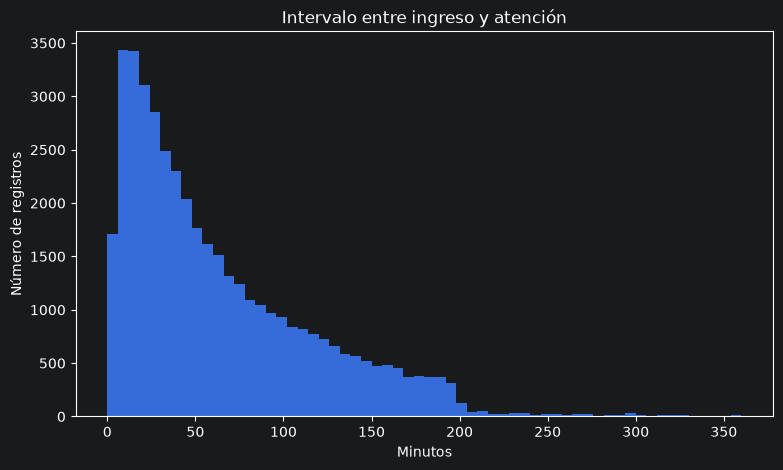

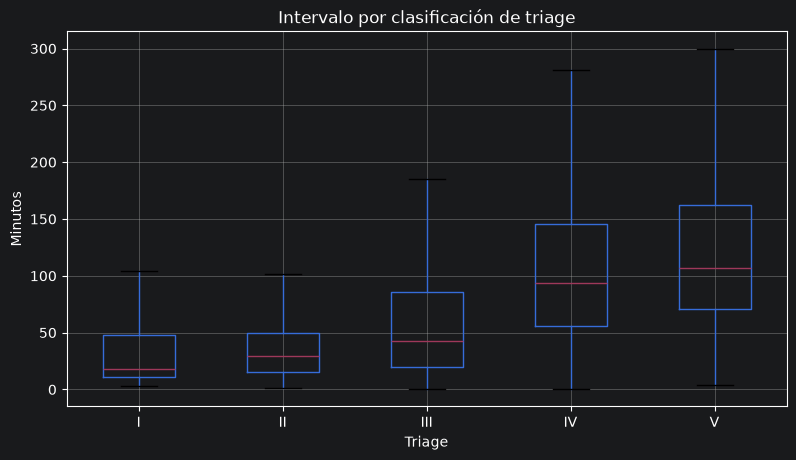

In [74]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(analisis["minutos"], bins=60)
ax.set(
    title="Intervalo entre ingreso y atención",
    xlabel="Minutos",
    ylabel="Número de registros"
)
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
analisis.boxplot(column="minutos", by="triage", ax=ax, showfliers=False)
ax.set(title="Intervalo por clasificación de triage",
       xlabel="Triage", ylabel="Minutos")
fig.suptitle("")
plt.show()

In [75]:
print("Máximo:", analisis["minutos"].max())
print("Percentil 99:", analisis["minutos"].quantile(0.99))
print("Registros exactamente en 360:", (analisis["minutos"] == 360).sum())
print("Registros entre 350 y 360:", analisis["minutos"].between(350, 360).sum())
print("Registros mayores de 360:", (analisis["minutos"] > 360).sum())

display(
    analisis.loc[analisis["minutos"] >= 350]
            .groupby(["triage", "minutos"])
            .size()
            .rename("registros")
            .reset_index()
            .sort_values(["triage", "minutos"])
)

display(analisis["triage"].value_counts(dropna=False))

Máximo: 360.0
Percentil 99: 211.0
Registros exactamente en 360: 3
Registros entre 350 y 360: 13
Registros mayores de 360: 0


,triage,minutos,registros
0,IV,352.0,2
1,IV,355.0,2
2,IV,357.0,2
3,IV,358.0,3
4,IV,360.0,3
5,V,356.0,1


triage
III    36282
IV      4280
II      1254
V        268
I         72
Name: count, dtype: int64

Shapiro-Wilk: W = 0.8907, p = 1.00551e-50
Tamaño de la muestra: 5000


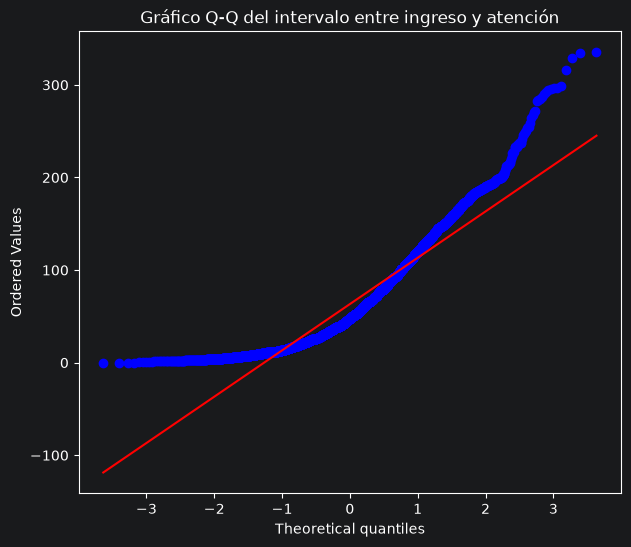

In [76]:
from scipy import stats
import matplotlib.pyplot as plt

muestra_qq = analisis["minutos"].sample(
    n=min(5000, len(analisis)),
    random_state=20261003
)

w, p = stats.shapiro(muestra_qq)

print(f"Shapiro-Wilk: W = {w:.4f}, p = {p:.6g}")
print("Tamaño de la muestra:", len(muestra_qq))

fig, ax = plt.subplots(figsize=(7, 6))
stats.probplot(muestra_qq, dist="norm", plot=ax)
ax.set_title("Gráfico Q-Q del intervalo entre ingreso y atención")
plt.show()

In [77]:
display(
    analisis["minutos"].agg(
        ["count", "mean", "median", "std", "min", "max", "skew"]
    ).to_frame("intervalo_minutos")
)

display(
    analisis.groupby("triage")["minutos"]
            .agg(["count", "mean", "median", "std", "min", "max"])
            .sort_index()
)

,intervalo_minutos
count,42156.000000
mean,63.506262
median,47.000000
std,53.934997
min,0.000000
max,360.000000
skew,1.245361


,count,mean,median,std,min,max
triage,,,,,,
I,72,34.277778,18.0,36.229403,3.0,160.0
II,1254,38.766348,29.0,33.801478,1.0,187.0
III,36282,58.647015,43.0,49.030580,0.0,199.0
IV,4280,108.521729,94.0,69.844688,0.0,360.0
V,268,126.063433,106.5,77.467643,4.0,356.0


In [78]:
analisis = analisis.copy()

# Cada bloque corresponde a una hora de ingreso en una IPS.
analisis["hora_bloque"] = analisis["ingreso_dt"].dt.floor("h")

conteo_horario = (
    analisis.groupby(["ips", "hora_bloque"], dropna=False)
            .size()
            .rename("ingresos_hora_ips")
            .reset_index()
)

display(conteo_horario.head())

display(
    conteo_horario["ingresos_hora_ips"]
    .agg(["count", "mean", "median", "std", "min", "max", "skew"])
    .to_frame("ingresos_por_hora_e_ips")
)

,ips,hora_bloque,ingresos_hora_ips
0,CENTRO HOSPITAL LA ROSA,2022-01-01 18:00:00,3
1,CENTRO HOSPITAL LA ROSA,2022-01-01 19:00:00,2
2,CENTRO HOSPITAL LA ROSA,2022-01-01 20:00:00,3
3,CENTRO HOSPITAL LA ROSA,2022-01-01 21:00:00,3
4,CENTRO HOSPITAL LA ROSA,2022-01-01 22:00:00,4


,ingresos_por_hora_e_ips
count,13409.000000
mean,3.143859
median,3.000000
std,2.201741
min,1.000000
max,16.000000
skew,1.323339


In [79]:
from scipy import stats
import numpy as np
import pandas as pd

grupo_iii = analisis.loc[analisis["triage"] == "III", "minutos"].dropna()
grupo_iv = analisis.loc[analisis["triage"] == "IV", "minutos"].dropna()

def ic_media(serie):
    n = len(serie)
    media = serie.mean()
    error = serie.std(ddof=1) / np.sqrt(n)
    margen = stats.t.ppf(0.975, df=n-1) * error
    return media - margen, media + margen

print("III:", len(grupo_iii), "IC 95 %:", ic_media(grupo_iii))
print("IV:", len(grupo_iv), "IC 95 %:", ic_media(grupo_iv))

# Prueba 1: diferencia de medias, sin suponer varianzas iguales
welch = stats.ttest_ind(grupo_iii, grupo_iv, equal_var=False)
print("Welch:", welch)

# Prueba 2: comparación de distribuciones mediante rangos
mann = stats.mannwhitneyu(
    grupo_iii, grupo_iv, alternative="two-sided", method="asymptotic"
)
print("Mann-Whitney:", mann)

III: 36282 IC 95 %: (np.float64(58.1424885299281), np.float64(59.15154156764095))
IV: 4280 IC 95 %: (np.float64(106.42866525232834), np.float64(110.61479269159689))
Welch: TtestResult(statistic=np.float64(-45.414953175275045), pvalue=np.float64(0.0), df=np.float64(4789.05059336485))
Mann-Whitney: MannwhitneyuResult(statistic=np.float64(41605088.5), pvalue=np.float64(0.0))


In [80]:
# Diferencia definida como media de III menos media de IV
diferencia = grupo_iii.mean() - grupo_iv.mean()

v_iii = grupo_iii.var(ddof=1) / len(grupo_iii)
v_iv = grupo_iv.var(ddof=1) / len(grupo_iv)

error_estandar = np.sqrt(v_iii + v_iv)
gl_welch = (v_iii + v_iv)**2 / (
    v_iii**2 / (len(grupo_iii) - 1)
    + v_iv**2 / (len(grupo_iv) - 1)
)

margen = stats.t.ppf(0.975, gl_welch) * error_estandar
ic_diferencia = (diferencia - margen, diferencia + margen)

print(f"Diferencia III - IV: {diferencia:.2f} minutos")
print(f"IC 95 %: ({ic_diferencia[0]:.2f}, {ic_diferencia[1]:.2f})")
print(f"Grados de libertad de Welch: {gl_welch:.2f}")

Diferencia III - IV: -49.87 minutos
IC 95 %: (-52.03, -47.72)
Grados de libertad de Welch: 4789.05
